In [7]:
import numpy as np
import pandas as pd
from matplotlib.pyplot import subplots
import sklearn.model_selection as skm
from ISLP import load_data, confusion_table
from ISLP.models import ModelSpec as MS
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error

In [8]:
from sklearn.tree import (DecisionTreeClassifier as DTC,
                          DecisionTreeRegressor as DTR,
                          plot_tree,
                          export_text)
from sklearn.metrics import (accuracy_score,
                             log_loss)
from sklearn.ensemble import \
     (RandomForestRegressor as RF,
      GradientBoostingRegressor as GBR)
from ISLP.bart import BART

In [33]:
df = pd.read_stata("dataset_merged.dta")

In [ ]:

# Transform advertisement types into binary columns
dummies = pd.get_dummies(df["ad_condition"], drop_first=True, dtype=int)
# Add those dummies to the dataframe and define as df2
df2 = pd.concat([df, dummies], axis=1)
# Rename binary columns for better readability
df2 = df2.rename(columns={
    1: "lostgirls_genre",
    2: "lostgirls_plain",
    3: "lostgirls_price",
    4: "stateline_genre",
    5: "stateline_plain",
    6: "stateline_price",
    "age_years": "age" 
})
# Group price ads across different genres
df2["price_ad"] = df2["lostgirls_price"] + df2["stateline_price"]
# Define the interaction term
df2["price_age"] = df2["price_ad"] * df2["age"]
# Group genre ads across different ad types; end result is stateline vs. lostgirls
df2["book_ad"] = df2["stateline_plain"] + df2["stateline_price"]
# Define a new column that takes lostgirls purchase information
df2["purchase"] = df2["purchased_203"]
# Insert the stateline purchase information into "purchase"
df2.loc[df2["book_ad"] == 1, "purchase"] = df2["purchased_303"]
# Define a new column that takes lostgirls search information
df2["search"] = df2["clicked_203"]
# Insert the stateline search information into "search"
df2.loc[df2["book_ad"] == 1, "search"] = df2["clicked_303"]
# Take observations that contains one of 2, 3, 5, 6 in the "ad_condition" column, and define as df3
df3 = df2[df2["ad_condition"].isin([2, 3, 5, 6])].copy()

# Ordinal categorical variables
categorical = [
    "ebooks", "printbooks",
    "romance_rank", "mystery_rank",
    "fantasy_rank", "scifi_rank"
]

income_dummies = [
    "income1", "income2", "income3", "income4", "income5"
]

# Remove missing observations
df3 = df3.dropna(
    subset=["purchase", "age"] + categorical + income_dummies
).copy()

# Convert income dummies into one ordinal variable
df3["income_bracket"] = np.select(
    [
        df3["income1"] == 1,
        df3["income2"] == 1,
        df3["income3"] == 1,
        df3["income4"] == 1,
        df3["income5"] == 1
    ],
    [1, 2, 3, 4, 5],
    default=6
)

# Select regression variables
columns = [
    "purchase",
    "price_ad", "age", "price_age", "book_ad",
    "income_bracket",
    "female", "black", "hispanic", "asian",
    "bachelor", "master", "some_college",
    "married", "divorced"
] + categorical

df4 = df3[columns].dropna().copy()


In [67]:
design = MS(df4.columns.drop('purchase'),  intercept=False).fit(df4)
Y = np.array(df4['purchase'])
D = design.fit_transform(df4)
feature_names = list(D.columns)
X = np.asarray(D)

In [68]:
clf = DTC(criterion='entropy',
          max_depth=3,
          random_state=0)        
clf.fit(X, Y)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current 

In [69]:
accuracy_score(Y, clf.predict(X))

0.9223231013114281

In [70]:
resid_dev = np.sum(log_loss(Y, clf.predict_proba(X)))
resid_dev

np.float64(0.2624690460129835)

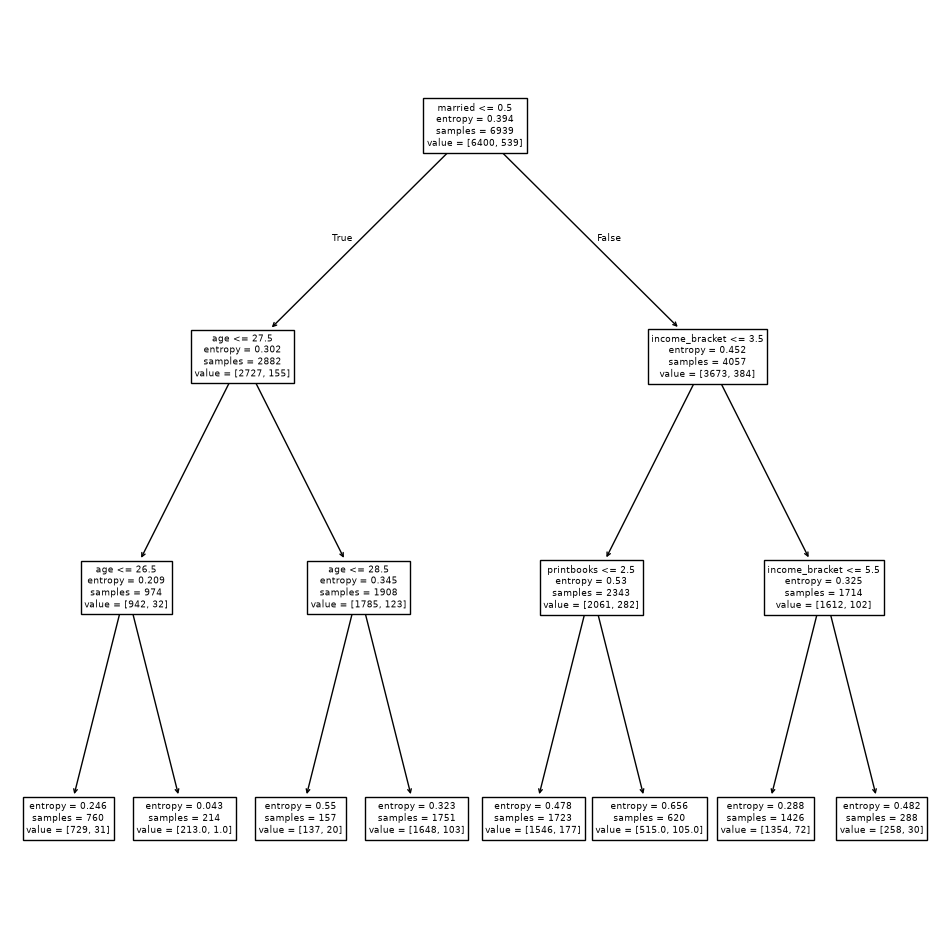

In [71]:
ax = subplots(figsize=(12,12))[1]
plot_tree(clf,
          feature_names=feature_names,
          ax=ax);

In [72]:
print(export_text(clf,
                  feature_names=feature_names,
                  show_weights=True))

|--- married <= 0.50
|   |--- age <= 27.50
|   |   |--- age <= 26.50
|   |   |   |--- weights: [729.00, 31.00] class: 0.0
|   |   |--- age >  26.50
|   |   |   |--- weights: [213.00, 1.00] class: 0.0
|   |--- age >  27.50
|   |   |--- age <= 28.50
|   |   |   |--- weights: [137.00, 20.00] class: 0.0
|   |   |--- age >  28.50
|   |   |   |--- weights: [1648.00, 103.00] class: 0.0
|--- married >  0.50
|   |--- income_bracket <= 3.50
|   |   |--- printbooks <= 2.50
|   |   |   |--- weights: [1546.00, 177.00] class: 0.0
|   |   |--- printbooks >  2.50
|   |   |   |--- weights: [515.00, 105.00] class: 0.0
|   |--- income_bracket >  3.50
|   |   |--- income_bracket <= 5.50
|   |   |   |--- weights: [1354.00, 72.00] class: 0.0
|   |   |--- income_bracket >  5.50
|   |   |   |--- weights: [258.00, 30.00] class: 0.0



In [73]:
validation = skm.ShuffleSplit(n_splits=1,
                              test_size=200,
                              random_state=0)
results = skm.cross_validate(clf,
                             D,
                             Y,
                             cv=validation)
results['test_score']


array([0.92])

In [74]:
(X_train,
 X_test,
 Y_train,
 Y_test) = skm.train_test_split(X,
                                   Y,
                                   test_size=0.5,
                                   random_state=0)

In [75]:
clf = DTC(criterion='entropy', random_state=0)
clf.fit(X_train, Y_train)
accuracy_score(Y_test, clf.predict(X_test))


0.8602305475504323

In [76]:
ccp_path = clf.cost_complexity_pruning_path(X_train, Y_train)
kfold = skm.KFold(10,
                  random_state=1,
                  shuffle=True)


In [77]:
grid = skm.GridSearchCV(clf,
                        {'ccp_alpha': ccp_path.ccp_alphas},
                        refit=True,
                        cv=kfold,
                        scoring='accuracy')
grid.fit(X_train, Y_train)
grid.best_score_


np.float64(0.9204344422048607)

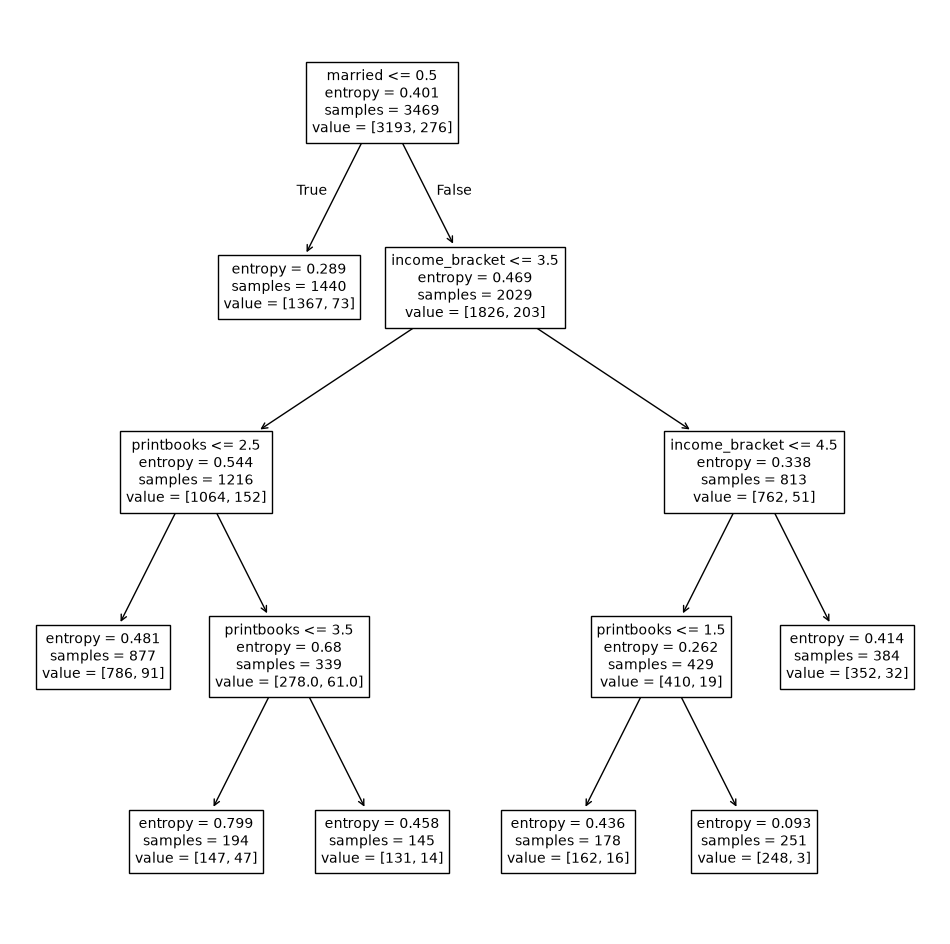

In [78]:
ax = subplots(figsize=(12, 12))[1]
best_ = grid.best_estimator_
plot_tree(best_,
          feature_names=feature_names,
          ax=ax);

In [79]:
best_.tree_.n_leaves


np.int64(7)

In [80]:
print(accuracy_score(Y_test,
                     best_.predict(X_test)))
confusion = confusion_table(best_.predict(X_test),
                            Y_test)
confusion


0.924207492795389


Truth,0.0,1.0
Predicted,,
0.0,3207,263
1.0,0,0


In [81]:
(x_train,
 x_test,
 y_train,
 y_test) = skm.train_test_split(X,
                                Y,
                                test_size=0.3,
                                random_state=0)

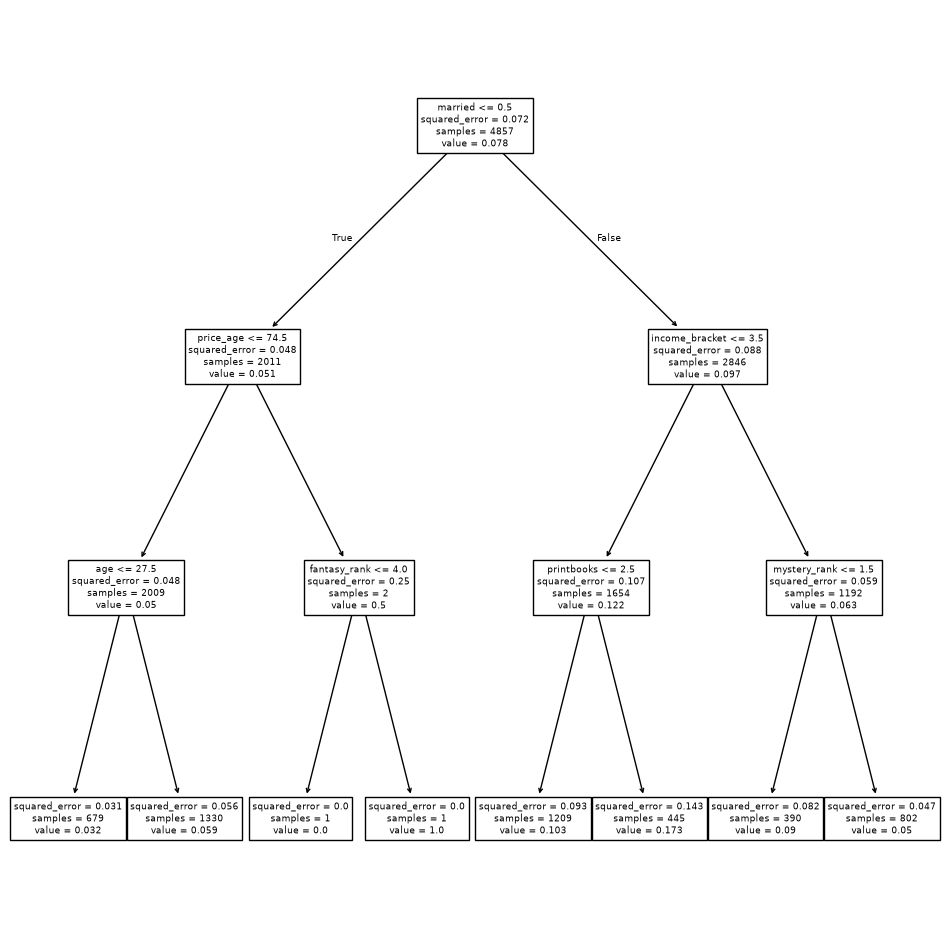

In [82]:
reg = DTR(max_depth=3)
reg.fit(x_train, y_train)
ax = subplots(figsize=(12,12))[1]
plot_tree(reg,
          feature_names=feature_names,
          ax=ax);

In [83]:
ccp_path = reg.cost_complexity_pruning_path(x_train, y_train)
kfold = skm.KFold(5,
                  shuffle=True,
                  random_state=10)
grid = skm.GridSearchCV(reg,
                        {'ccp_alpha': ccp_path.ccp_alphas},
                        refit=True,
                        cv=kfold,
                        scoring='neg_mean_squared_error')
G = grid.fit(x_train, y_train)


In [84]:
best_ = grid.best_estimator_
np.mean((y_test - best_.predict(x_test))**2)


np.float64(0.07025423927083287)

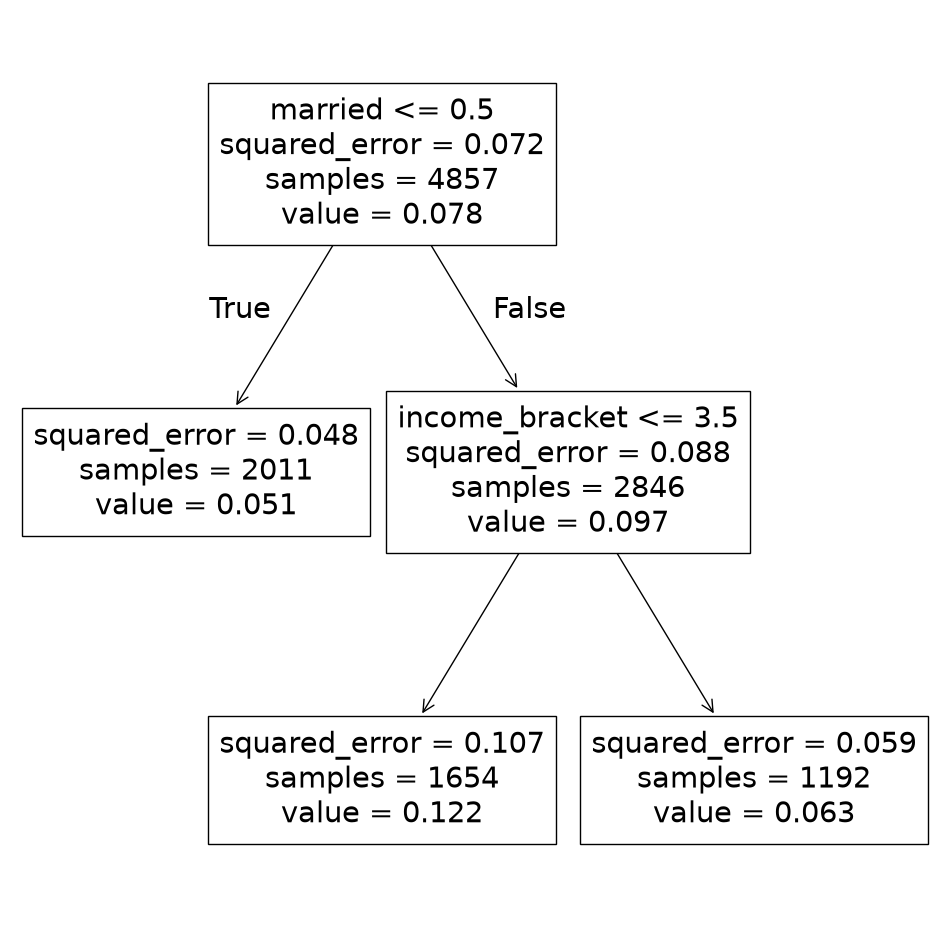

In [85]:
ax = subplots(figsize=(12,12))[1]
plot_tree(G.best_estimator_,
          feature_names=feature_names,
          ax=ax);

In [86]:
bag_boston = RF(max_features=X_train.shape[1], random_state=0)
bag_boston.fit(x_train, y_train)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",20
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples

np.float64(0.07278597502401538)

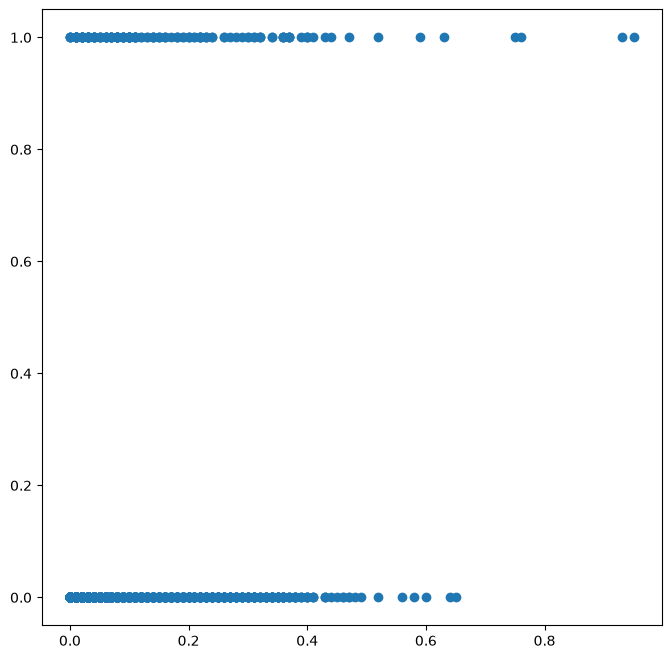

In [87]:
ax = subplots(figsize=(8,8))[1]
y_hat_bag = bag_boston.predict(x_test)
ax.scatter(y_hat_bag, y_test)
np.mean((y_test - y_hat_bag)**2)


In [88]:
bag_boston = RF(max_features=X_train.shape[1],
                n_estimators=500,
                random_state=0).fit(x_train, y_train)
y_hat_bag = bag_boston.predict(x_test)
np.mean((y_test - y_hat_bag)**2)

np.float64(0.07200959654178675)

In [89]:
RF_boston = RF(max_features=6,
               random_state=0,
               n_estimators=500).fit(x_train, y_train)
y_hat_RF = RF_boston.predict(x_test)
np.mean((y_test - y_hat_RF)**2)


np.float64(0.06897777329490873)

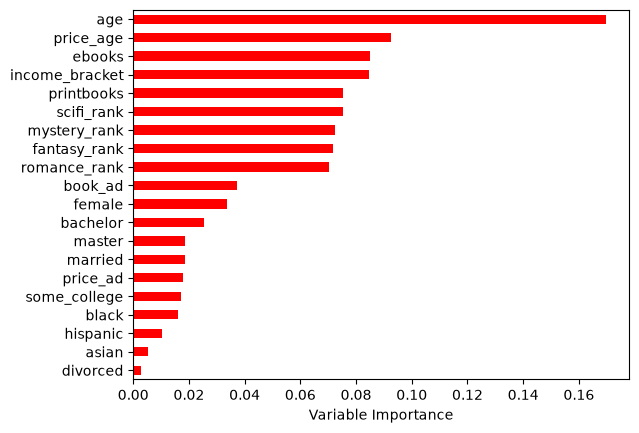

In [90]:
feature_imp = pd.DataFrame(
    {'importance':RF_boston.feature_importances_},
    index=feature_names)
feature_imp.sort_values(by='importance', axis=0, ascending=True).tail(20).plot(kind='barh', color='r', )
plt.xlabel('Variable Importance')
plt.gca().legend_ = None

In [91]:
boost_boston = GBR(n_estimators=5000,
                   learning_rate=0.001,
                   max_depth=3,
                   random_state=0)
boost_boston.fit(x_train, y_train)


,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.001
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",5000
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are""friedman_mse"" for the mean squared error with improvement score byFriedman, ""squared_error"" for mean squared error. The default value of""friedman_mse"" is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in thele

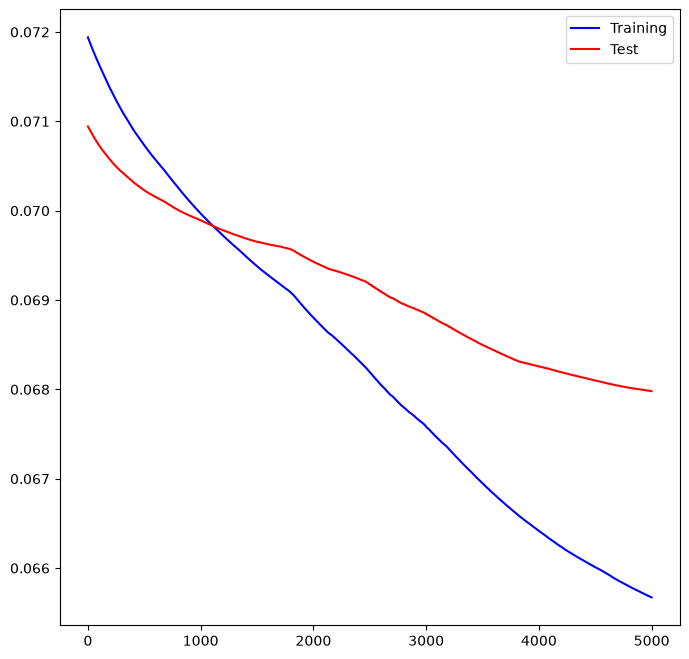

In [92]:
test_error = np.zeros_like(boost_boston.train_score_)
for idx, y_ in enumerate(boost_boston.staged_predict(x_test)):
   test_error[idx] = np.mean((y_test - y_)**2)

plot_idx = np.arange(boost_boston.train_score_.shape[0])
ax = subplots(figsize=(8,8))[1]
ax.plot(plot_idx,
        boost_boston.train_score_,
        'b',
        label='Training')
ax.plot(plot_idx,
        test_error,
        'r',
        label='Test')

ax.legend();

In [93]:
y_hat_boost = boost_boston.predict(x_test);
np.mean((y_test - y_hat_boost)**2)


np.float64(0.06798053454032198)

In [94]:
boost_boston = GBR(n_estimators=5000,
                   learning_rate=0.2,
                   max_depth=3,
                   random_state=0)
boost_boston.fit(x_train,
                 y_train)
y_hat_boost = boost_boston.predict(x_test);
np.mean((y_test - y_hat_boost)**2)

np.float64(0.09904219397867964)

In [95]:
bart_boston = BART(random_state=0, burnin=5, ndraw=15)
bart_boston.fit(x_train, y_train)


,num_trees,200
,num_particles,10
,max_stages,5000
,split_prob,<function BAR...t 0x311b774c0>
,min_depth,0
,std_scale,2
,split_prior,None
,ndraw,15
,burnin,5
,sigma_prior,"(5, ...)"
,num_quantile,50


In [98]:
yhat_test = bart_boston.predict(x_test.astype(np.float32))
np.mean((y_test - yhat_test)**2)


np.float64(0.06934718062250056)

In [99]:
var_inclusion = pd.Series(bart_boston.variable_inclusion_.mean(0),
                               index=D.columns)
var_inclusion


price_ad          15.066667
age               15.066667
price_age         13.533333
book_ad           15.200000
income_bracket    18.933333
female            15.066667
black             16.066667
hispanic          15.933333
asian             13.800000
bachelor          12.933333
master            16.333333
some_college      12.666667
married           14.000000
divorced          15.066667
ebooks            16.466667
printbooks        16.466667
romance_rank      15.666667
mystery_rank      14.733333
fantasy_rank      13.600000
scifi_rank        14.866667
dtype: float64